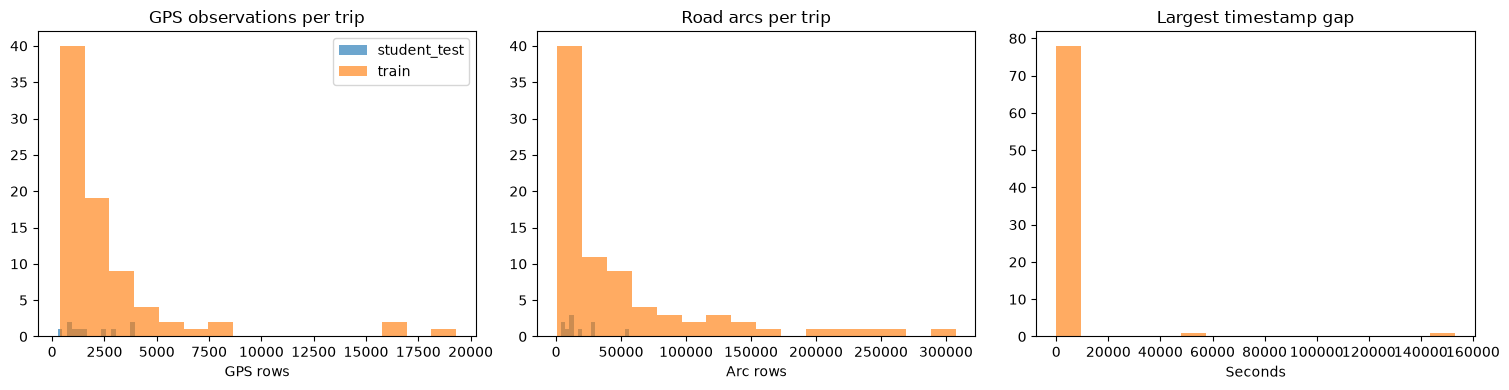

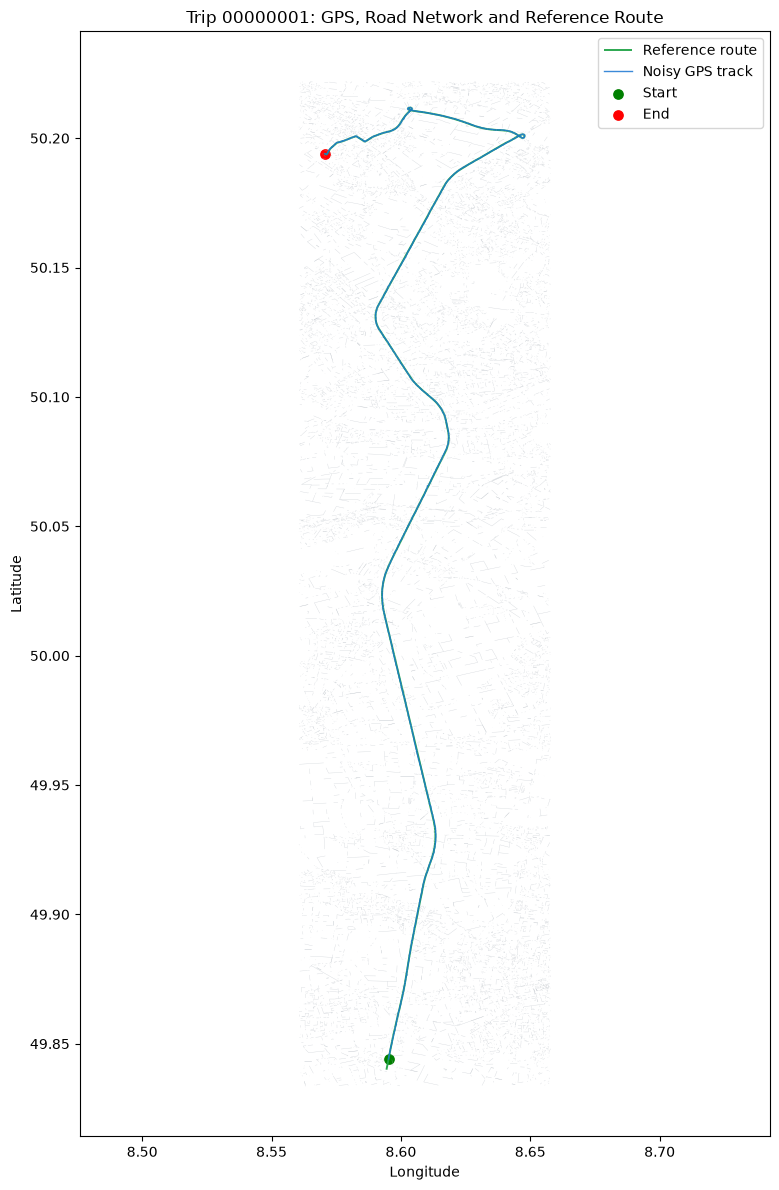

,trips,gps_observations,road_nodes,road_arcs,reference_route_arcs
partition,,,,,
student_test,10,19160,90689,185041,3477
train,80,208417,1933485,3876904,31336


,total
missing_cells,0
duplicate_track_rows,0
invalid_coordinates,0
invalid_arc_references,0
invalid_route_arc_ids,0


one_second_steps                gap_over_one_second               \
                          sum  median    max                 sum median   max   
partition                                                                       
student_test            18886  1316.0   3916                 264    1.0   206   
train                  201048  1525.5  19282                7286   15.5  1268   

             maximum_gap_s                   
                       sum median       max  
partition                                    
student_test         255.0    2.0     210.0  
train             216512.0   11.0  153064.0

EDA outputs written to: c:\Users\Suhas Prusty\TEAM6_PATH_SNAP_ML\outputs\eda
Interactive Folium map saved to: c:\Users\Suhas Prusty\TEAM6_PATH_SNAP_ML\outputs\eda\trip_00000001_map.html


In [2]:
from pathlib import Path
from zipfile import ZipFile

import folium
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd

ROOT = Path.cwd()
ARCHIVE_PATH = ROOT / "Student folder.zip"
EXTRACT_ROOT = ROOT / "data"
DATA_ROOT = EXTRACT_ROOT / "Student folder"
OUTPUT_ROOT = ROOT / "outputs" / "eda"

if not DATA_ROOT.exists():
    if not ARCHIVE_PATH.exists():
        raise FileNotFoundError(f"Dataset ZIP not found: {ARCHIVE_PATH}")
    with ZipFile(ARCHIVE_PATH) as archive:
        archive.extractall(EXTRACT_ROOT)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


def read_table(path, columns, dtypes):
    return pd.read_csv(path, sep=r"\s+", names=columns, dtype=dtypes, header=None)


def load_trip(trip_dir, partition):
    trip_id = trip_dir.name
    return {
        "trip_id": trip_id,
        "partition": partition,
        "track": read_table(
            trip_dir / f"{trip_id}.track",
            ["longitude", "latitude", "timestamp_s"],
            {"longitude": "float64", "latitude": "float64", "timestamp_s": "float64"},
        ),
        "nodes": read_table(
            trip_dir / f"{trip_id}.nodes",
            ["longitude", "latitude"],
            {"longitude": "float64", "latitude": "float64"},
        ),
        "arcs": read_table(
            trip_dir / f"{trip_id}.arcs",
            ["from_node_id", "to_node_id"],
            {"from_node_id": "int64", "to_node_id": "int64"},
        ),
        "route": read_table(
            trip_dir / f"{trip_id}.route",
            ["arc_id"],
            {"arc_id": "int64"},
        ),
    }


def load_partition(partition):
    partition_root = DATA_ROOT / partition
    return [
        load_trip(trip_dir, partition)
        for trip_dir in sorted(partition_root.iterdir())
        if trip_dir.is_dir()
    ]


def count_components(node_count, arcs):
    parent = list(range(node_count))

    def find(node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    for source, target in arcs[["from_node_id", "to_node_id"]].itertuples(index=False):
        source_root = find(int(source))
        target_root = find(int(target))
        if source_root != target_root:
            parent[target_root] = source_root

    return len({find(node) for node in range(node_count)})


def create_summaries(trips):
    inventory_rows = []
    quality_rows = []
    timestamp_rows = []
    network_rows = []

    for trip in trips:
        track = trip["track"]
        nodes = trip["nodes"]
        arcs = trip["arcs"]
        route = trip["route"]
        timestamp_gaps = track["timestamp_s"].diff().dropna()
        degree = pd.concat([arcs["from_node_id"], arcs["to_node_id"]]).value_counts()

        inventory_rows.append(
            {
                "partition": trip["partition"],
                "trip_id": trip["trip_id"],
                "track_rows": len(track),
                "node_rows": len(nodes),
                "arc_rows": len(arcs),
                "route_rows": len(route),
            }
        )

        quality_rows.append(
            {
                "partition": trip["partition"],
                "trip_id": trip["trip_id"],
                "missing_cells": int(
                    track.isna().sum().sum()
                    + nodes.isna().sum().sum()
                    + arcs.isna().sum().sum()
                    + route.isna().sum().sum()
                ),
                "duplicate_track_rows": int(track.duplicated().sum()),
                "invalid_coordinates": int(
                    ((track["longitude"].abs() > 180) | (track["latitude"].abs() > 90)).sum()
                ),
                "invalid_arc_references": int(
                    (
                        (arcs["from_node_id"] < 0)
                        | (arcs["to_node_id"] < 0)
                        | (arcs["from_node_id"] >= len(nodes))
                        | (arcs["to_node_id"] >= len(nodes))
                    ).sum()
                ),
                "invalid_route_arc_ids": int(
                    ((route["arc_id"] < 0) | (route["arc_id"] >= len(arcs))).sum()
                ),
            }
        )

        timestamp_rows.append(
            {
                "partition": trip["partition"],
                "trip_id": trip["trip_id"],
                "first_timestamp_s": track["timestamp_s"].min(),
                "last_timestamp_s": track["timestamp_s"].max(),
                "non_increasing_steps": int((timestamp_gaps <= 0).sum()),
                "one_second_steps": int((timestamp_gaps == 1).sum()),
                "gap_over_one_second": int((timestamp_gaps > 1).sum()),
                "maximum_gap_s": timestamp_gaps.max() if not timestamp_gaps.empty else 0,
                "median_gap_s": timestamp_gaps.median() if not timestamp_gaps.empty else 0,
            }
        )

        network_rows.append(
            {
                "partition": trip["partition"],
                "trip_id": trip["trip_id"],
                "nodes": len(nodes),
                "arcs": len(arcs),
                "isolated_nodes": int(len(nodes) - len(degree)),
                "weak_components": count_components(len(nodes), arcs),
                "mean_observed_degree": float(degree.mean()) if not degree.empty else 0,
            }
        )

    return (
        pd.DataFrame(inventory_rows),
        pd.DataFrame(quality_rows),
        pd.DataFrame(timestamp_rows),
        pd.DataFrame(network_rows),
    )


def make_segments(nodes, arcs, limit=None):
    if limit is not None and len(arcs) > limit:
        indexes = np.linspace(0, len(arcs) - 1, limit, dtype=int)
        arcs = arcs.iloc[indexes]

    source = nodes.iloc[arcs["from_node_id"].to_numpy()][["longitude", "latitude"]].to_numpy()
    target = nodes.iloc[arcs["to_node_id"].to_numpy()][["longitude", "latitude"]].to_numpy()
    return np.stack([source, target], axis=1)


def create_static_map(trip):
    nodes = trip["nodes"]
    arcs = trip["arcs"]
    track = trip["track"]
    route_arcs = arcs.iloc[trip["route"]["arc_id"].drop_duplicates().to_numpy()]

    fig, axis = plt.subplots(figsize=(8, 12))
    axis.add_collection(
        LineCollection(
            make_segments(nodes, arcs, limit=25000),
            colors="#b8bec5",
            linewidths=0.25,
            alpha=0.65,
        )
    )
    axis.add_collection(
        LineCollection(
            make_segments(nodes, route_arcs),
            colors="#20a347",
            linewidths=1.4,
            alpha=0.95,
            label="Reference route",
        )
    )
    axis.plot(
        track["longitude"],
        track["latitude"],
        color="#1976d2",
        linewidth=1,
        alpha=0.85,
        label="Noisy GPS track",
    )
    axis.scatter(track["longitude"].iloc[0], track["latitude"].iloc[0], color="green", s=45, label="Start")
    axis.scatter(track["longitude"].iloc[-1], track["latitude"].iloc[-1], color="red", s=45, label="End")
    axis.set_title(f"Trip {trip['trip_id']}: GPS, Road Network and Reference Route")
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    axis.legend()
    axis.set_aspect("equal", adjustable="datalim")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"trip_{trip['trip_id']}_overview.png", dpi=180)
    plt.show()
    plt.close(fig)


def create_distribution_plot(inventory, timestamps):
    merged = inventory.merge(
        timestamps[["partition", "trip_id", "maximum_gap_s"]],
        on=["partition", "trip_id"],
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for partition, group in merged.groupby("partition"):
        axes[0].hist(group["track_rows"], bins=16, alpha=0.65, label=partition)
        axes[1].hist(group["arc_rows"], bins=16, alpha=0.65, label=partition)
        axes[2].hist(group["maximum_gap_s"], bins=16, alpha=0.65, label=partition)

    axes[0].set_title("GPS observations per trip")
    axes[0].set_xlabel("GPS rows")
    axes[1].set_title("Road arcs per trip")
    axes[1].set_xlabel("Arc rows")
    axes[2].set_title("Largest timestamp gap")
    axes[2].set_xlabel("Seconds")
    axes[0].legend()

    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / "dataset_distributions.png", dpi=180)
    plt.show()
    plt.close(fig)


def create_folium_map(trip):
    nodes = trip["nodes"]
    arcs = trip["arcs"]
    track = trip["track"]
    route_arcs = arcs.iloc[trip["route"]["arc_id"].drop_duplicates().to_numpy()]

    fmap = folium.Map(
        location=[track["latitude"].mean(), track["longitude"].mean()],
        zoom_start=14,
        control_scale=True,
    )

    network_layer = folium.FeatureGroup(name="Road network (sampled)", show=False)
    for segment in make_segments(nodes, arcs, limit=8000):
        folium.PolyLine(
            [(segment[0][1], segment[0][0]), (segment[1][1], segment[1][0])],
            color="#9aa0a6",
            weight=1,
            opacity=0.45,
        ).add_to(network_layer)
    network_layer.add_to(fmap)

    route_layer = folium.FeatureGroup(name="Reference route")
    for segment in make_segments(nodes, route_arcs):
        folium.PolyLine(
            [(segment[0][1], segment[0][0]), (segment[1][1], segment[1][0])],
            color="#20a347",
            weight=4,
            opacity=0.9,
        ).add_to(route_layer)
    route_layer.add_to(fmap)

    gps_layer = folium.FeatureGroup(name="Noisy GPS observations")
    step = max(1, len(track) // 1000)
    for row in track.iloc[::step].itertuples(index=False):
        folium.CircleMarker(
            location=(row.latitude, row.longitude),
            radius=2,
            color="#1976d2",
            fill=True,
            fill_opacity=0.7,
            popup=f"Timestamp: {row.timestamp_s:g}s",
        ).add_to(gps_layer)
    gps_layer.add_to(fmap)

    folium.Marker(
        [track["latitude"].iloc[0], track["longitude"].iloc[0]],
        tooltip="Start",
        icon=folium.Icon(color="green"),
    ).add_to(fmap)

    folium.Marker(
        [track["latitude"].iloc[-1], track["longitude"].iloc[-1]],
        tooltip="End",
        icon=folium.Icon(color="red"),
    ).add_to(fmap)

    folium.LayerControl(collapsed=False).add_to(fmap)
    output_path = OUTPUT_ROOT / f"trip_{trip['trip_id']}_map.html"
    fmap.save(output_path)
    return output_path


trips = load_partition("train") + load_partition("student_test")
inventory, quality, timestamps, networks = create_summaries(trips)

inventory.to_csv(OUTPUT_ROOT / "trip_inventory.csv", index=False)
quality.to_csv(OUTPUT_ROOT / "data_quality.csv", index=False)
timestamps.to_csv(OUTPUT_ROOT / "timestamp_summary.csv", index=False)
networks.to_csv(OUTPUT_ROOT / "network_summary.csv", index=False)

selected_trip = next(
    trip
    for trip in trips
    if trip["partition"] == "train" and trip["trip_id"] == "00000001"
)

create_distribution_plot(inventory, timestamps)
create_static_map(selected_trip)
folium_map_path = create_folium_map(selected_trip)

display(inventory.groupby("partition").agg(
    trips=("trip_id", "count"),
    gps_observations=("track_rows", "sum"),
    road_nodes=("node_rows", "sum"),
    road_arcs=("arc_rows", "sum"),
    reference_route_arcs=("route_rows", "sum"),
))

display(quality.sum(numeric_only=True).to_frame("total"))
display(timestamps.groupby("partition")[["one_second_steps", "gap_over_one_second", "maximum_gap_s"]].agg(["sum", "median", "max"]))

print(f"EDA outputs written to: {OUTPUT_ROOT}")
print(f"Interactive Folium map saved to: {folium_map_path}")